# Uncertainty and Alerts

Đánh giá **độ tin cậy vận hành** của dự báo để trả lời **RQ4**: khoảng dự báo và cảnh báo tuần cao điểm đáng tin đến mức nào?

So sánh hai cách tạo khoảng dự báo:
- **Khoảng có sẵn của mô hình nền tảng:** các phân vị do chính mô hình đưa ra (Notebook 7, mục 4) — khoảng **80%** từ phân vị 10%–90% cho mọi mô hình nền tảng, khoảng **90%** từ phân vị 5%–95% cho Chronos-2.
- **Khoảng conformal:** dựng quanh dự báo điểm của bất kỳ mô hình nào, độ rộng tỷ lệ với mức nhu cầu gần đây của khu phố (giống Notebook 5). Ngưỡng được hiệu chuẩn trên **đoạn kiểm tra ngay trước** — tức là chỉ dùng các dự báo đã kiểm chứng xong trước mốc hiện tại.

Vì khoảng conformal cần đoạn trước để hiệu chuẩn, mọi phương pháp được đánh giá trên **8 mốc** (từ 07/2022 đến 01/2026), dùng biến mục tiêu chính `n`.

**Dữ liệu đầu vào:** `SF_Tree_Benchmark_Predictions.csv` và `bench_02_overall.csv` (Notebook 7), `SF_Tree_Weekly_Features.csv` (Notebook 3).

## **1. Khởi tạo và nạp dữ liệu**

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")
sns.set_style("ticks")
os.makedirs("../Outputs/figures", exist_ok=True)
os.makedirs("../Outputs/tables", exist_ok=True)

du_bao = pd.read_csv("../Data/processed/SF_Tree_Benchmark_Predictions.csv", parse_dates=["moc", "week_start"])
du_bao = du_bao[du_bao["bien"] == "n"].copy()
tong_hop = pd.read_csv("../Outputs/tables/bench_02_overall.csv")
feat = pd.read_csv("../Data/processed/SF_Tree_Weekly_Features.csv", parse_dates=["week_start"])
feat = feat.sort_values(["nbhd", "week_start"])

# Ngưỡng "tuần cao điểm" của mỗi khu phố: phân vị 90% của 52 tuần gần nhất, tính đến hết tuần hiện tại
# (chỉ dùng số liệu đã biết lúc đưa ra dự báo, và tự cập nhật theo xu hướng của nhu cầu)
feat["nguong_cao"] = feat.groupby("nbhd")["n"].transform(lambda s: s.rolling(52).quantile(0.9))
du_bao = du_bao.merge(feat[["nbhd", "week_start", "n", "n_ma4", "nguong_cao"]], on=["nbhd", "week_start"], how="left")

MOC = sorted(du_bao["moc"].unique())
MOC_DANH_GIA = MOC[1:]          # mốc đầu tiên chỉ dùng để hiệu chuẩn khoảng conformal
print("Số dòng dự báo (biến n):", f"{len(du_bao):,}")
print("Các mốc đánh giá:", [pd.Timestamp(m).strftime("%m/%Y") for m in MOC_DANH_GIA])

Số dòng dự báo (biến n): 115,128
Các mốc đánh giá: ['07/2022', '01/2023', '07/2023', '01/2024', '07/2024', '01/2025', '07/2025', '01/2026']


In [2]:
# Chọn mô hình: mô hình huấn luyện riêng tốt nhất và mô hình nền tảng tốt nhất theo MAE ở Notebook 7
co_phan_vi = du_bao.dropna(subset=["q10"])["mo_hinh"].unique()
TOT_HUAN_LUYEN = tong_hop[tong_hop["ho"].isin(["Học máy", "Mô hình đếm"])]["mo_hinh"].iloc[0]
TOT_NEN_TANG = tong_hop[tong_hop["mo_hinh"].isin(co_phan_vi)]["mo_hinh"].iloc[0]
NEN_TANG = [m for m in tong_hop["mo_hinh"] if m in co_phan_vi]
print("Mô hình huấn luyện riêng tốt nhất:", TOT_HUAN_LUYEN)
print("Mô hình nền tảng tốt nhất        :", TOT_NEN_TANG)
print("Các mô hình nền tảng có phân vị  :", NEN_TANG)

Mô hình huấn luyện riêng tốt nhất: Random Forest
Mô hình nền tảng tốt nhất        : TimesFM 2.5
Các mô hình nền tảng có phân vị  : ['TimesFM 2.5', 'Chronos-Bolt Small', 'Chronos-Bolt Base', 'Chronos-2', 'Chronos-2 + biến ngoài']


## **2. Dựng khoảng dự báo**

**Khoảng conformal** cho mức bao phủ mục tiêu 80% hoặc 90%, làm theo ba bước:
1. Trên đoạn kiểm tra ngay trước, tính **sai số chuẩn hoá** của mọi khu phố – tuần: sai số tuyệt đối chia cho (trung bình 4 tuần gần nhất + 1).
2. Lấy mức sai số chuẩn hoá mà 80% (hoặc 90%) số điểm nằm dưới, có hiệu chỉnh nhỏ theo số điểm (công thức conformal chuẩn); gọi là **hệ số khoảng**.
3. Khoảng dự báo = dự báo điểm ± hệ số khoảng × (trung bình 4 tuần gần nhất + 1), cận dưới không nhỏ hơn 0 — khu phố có nhu cầu gần đây cao thì khoảng rộng hơn.

Khoảng conformal được dựng cho ba dự báo điểm: mô hình huấn luyện riêng tốt nhất, mô hình nền tảng tốt nhất và mốc "Trung bình 4 tuần".

In [3]:
def khoang_conformal(ten, muc):
    d = du_bao[du_bao["mo_hinh"] == ten]
    out = []
    for truoc, hien_tai in zip(MOC[:-1], MOC[1:]):
        cal = d[d["moc"] == truoc]
        test = d[d["moc"] == hien_tai].copy()
        s = (cal["y"] - cal["du_bao"]).abs() / (cal["n_ma4"] + 1)
        m = len(s)
        q_hat = np.quantile(s, min(1.0, np.ceil((m + 1) * muc) / m))
        test["duoi"] = np.clip(test["du_bao"] - q_hat * (test["n_ma4"] + 1), 0, None)
        test["tren"] = test["du_bao"] + q_hat * (test["n_ma4"] + 1)
        out.append(test)
    return pd.concat(out).assign(phuong_phap=f"Conformal quanh {ten}", muc=muc)

def khoang_co_san(ten, muc):
    cot = {0.8: ("q10", "q90"), 0.9: ("q05", "q95")}[muc]
    d = du_bao[(du_bao["mo_hinh"] == ten) & du_bao["moc"].isin(MOC_DANH_GIA)].dropna(subset=list(cot)).copy()
    if d.empty:
        return None
    d["duoi"], d["tren"] = d[cot[0]], d[cot[1]]
    return d.assign(phuong_phap=f"Có sẵn: {ten}", muc=muc)

khoang = []
for muc in [0.8, 0.9]:
    for ten in [TOT_HUAN_LUYEN, TOT_NEN_TANG, "Trung bình 4 tuần"]:
        khoang.append(khoang_conformal(ten, muc))
    for ten in NEN_TANG:
        k = khoang_co_san(ten, muc)
        if k is not None:
            khoang.append(k)
khoang = pd.concat(khoang, ignore_index=True)
khoang["trong_khoang"] = (khoang["y"] >= khoang["duoi"]) & (khoang["y"] <= khoang["tren"])
khoang.groupby(["muc", "phuong_phap"]).size().unstack(0)

muc,0.8,0.9
phuong_phap,,
Conformal quanh Random Forest,8528.0,8528.0
Conformal quanh TimesFM 2.5,8528.0,8528.0
Conformal quanh Trung bình 4 tuần,8528.0,8528.0
Có sẵn: Chronos-2,8528.0,8528.0
Có sẵn: Chronos-2 + biến ngoài,8528.0,8528.0
Có sẵn: Chronos-Bolt Base,8528.0,NaN
Có sẵn: Chronos-Bolt Small,8528.0,NaN
Có sẵn: TimesFM 2.5,8528.0,NaN


## **3. Độ tin cậy của khoảng dự báo**

- **Độ bao phủ:** tỷ lệ tuần mà số yêu cầu thực tế nằm trong khoảng — càng sát mức mục tiêu (80% hoặc 90%) càng tốt.
- **Độ rộng trung bình:** khoảng hẹp hơn thì hữu ích hơn cho lập kế hoạch, nếu vẫn đủ độ bao phủ.
- **Điểm số khoảng (interval score):** độ rộng cộng với phần phạt khi giá trị thực nằm ngoài khoảng (phạt bằng khoảng cách nằm ngoài, nhân 10 lần với khoảng 80% và 20 lần với khoảng 90%) — gộp cả hai tiêu chí trên thành một con số, **càng thấp càng tốt**.
- **Số khu phố đạt:** số khu phố (trên 41) có độ bao phủ không thấp hơn mục tiêu quá 5 điểm %.

In [4]:
def diem_so_khoang(d):
    a = 1 - d["muc"]
    return (d["tren"] - d["duoi"]) + (2 / a) * (d["duoi"] - d["y"]).clip(lower=0) + (2 / a) * (d["y"] - d["tren"]).clip(lower=0)

khoang["diem_so"] = diem_so_khoang(khoang)
rows = []
for (muc, pp), g in khoang.groupby(["muc", "phuong_phap"]):
    bp_khu_pho = g.groupby("nbhd")["trong_khoang"].mean()
    rows.append({"muc_tieu_%": int(muc * 100), "phuong_phap": pp,
                 "bao_phu_%": g["trong_khoang"].mean() * 100,
                 "do_rong_tb": (g["tren"] - g["duoi"]).mean(),
                 "diem_so_khoang": g["diem_so"].mean(),
                 "khu_pho_dat": f"{int((bp_khu_pho >= muc - 0.05).sum())}/{len(bp_khu_pho)}",
                 "bao_phu_thap_nhat_%": bp_khu_pho.min() * 100})
do_tin_cay = pd.DataFrame(rows).sort_values(["muc_tieu_%", "diem_so_khoang"]).reset_index(drop=True).round(2)
do_tin_cay

,muc_tieu_%,phuong_phap,bao_phu_%,do_rong_tb,diem_so_khoang,khu_pho_dat,bao_phu_thap_nhat_%
0,80,Có sẵn: Chronos-2 + biến ngoài,73.78,7.09,11.96,24/41,41.83
1,80,Có sẵn: Chronos-2,75.41,6.83,12.02,29/41,49.04
2,80,Có sẵn: Chronos-Bolt Small,78.44,6.80,12.03,34/41,45.19
3,80,Có sẵn: Chronos-Bolt Base,77.13,6.48,12.12,24/41,68.75
4,80,Có sẵn: TimesFM 2.5,77.46,6.53,12.15,31/41,57.21
5,80,Conformal quanh Random Forest,80.85,8.01,12.97,38/41,72.60
6,80,Conformal quanh TimesFM 2.5,80.18,7.78,13.00,38/41,72.12
7,80,Conformal quanh Trung bình 4 tuần,80.95,8.20,13.15,37/41,73.08
8,90,Có sẵn: Chronos-2 + biến ngoài,85.59,9.73,15.03,31/41,56.73
9,90,Có sẵn: Chronos-2,86.55,9.42,15.23,29/41,75.96


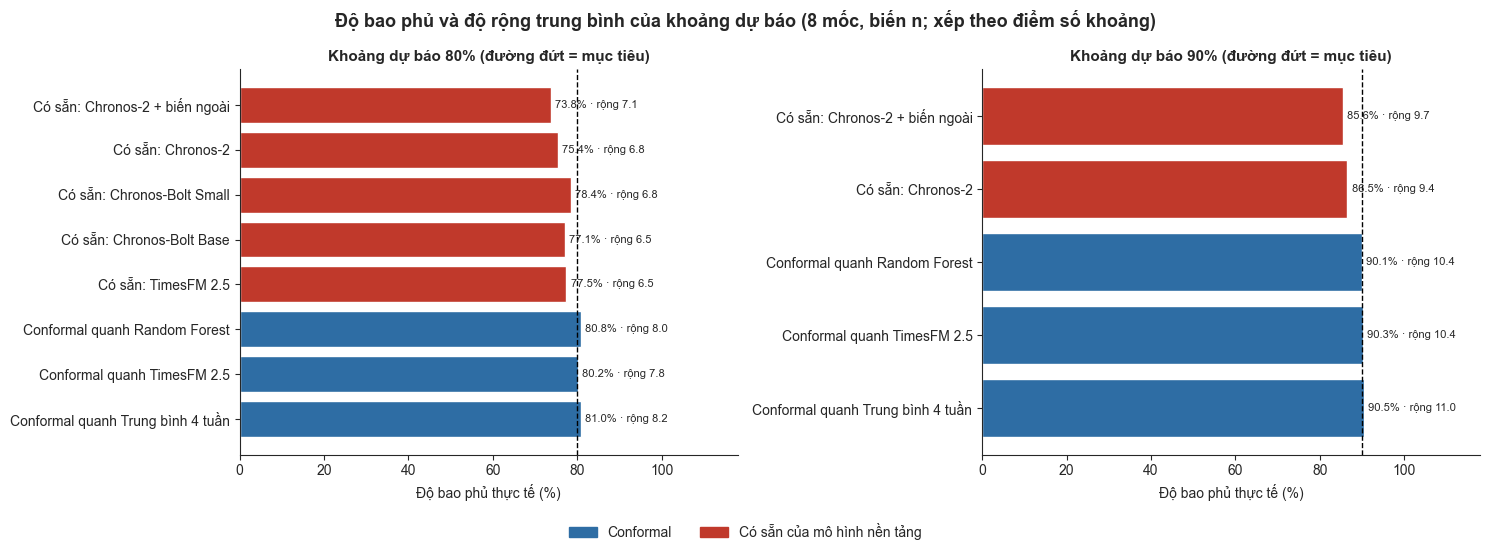

In [5]:
# Biểu đồ 1: độ bao phủ của từng phương pháp (thanh) kèm độ rộng trung bình (số bên phải)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, muc in zip(axes, [80, 90]):
    d = do_tin_cay[do_tin_cay["muc_tieu_%"] == muc].iloc[::-1]
    mau = ["#2E6DA4" if p.startswith("Conformal") else "#C0392B" for p in d["phuong_phap"]]
    ax.barh(d["phuong_phap"], d["bao_phu_%"], color=mau)
    for y, (bp, rong) in enumerate(zip(d["bao_phu_%"], d["do_rong_tb"])):
        ax.text(bp + 1, y, f"{bp:.1f}% · rộng {rong:.1f}", va="center", fontsize=8)
    ax.axvline(muc, color="black", linestyle="--", linewidth=1)
    ax.set_xlim(0, 118)
    ax.set_xlabel("Độ bao phủ thực tế (%)")
    ax.set_title(f"Khoảng dự báo {muc}% (đường đứt = mục tiêu)", fontsize=11, fontweight="bold")
    sns.despine(ax=ax)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color="#2E6DA4", label="Conformal"), Patch(color="#C0392B", label="Có sẵn của mô hình nền tảng")],
           loc="lower center", ncol=2, frameon=False)
fig.suptitle("Độ bao phủ và độ rộng trung bình của khoảng dự báo (8 mốc, biến n; xếp theo điểm số khoảng)",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.savefig("../Outputs/figures/fig_u01_coverage_vs_width.png", dpi=300)
plt.show()

**Nhận xét:** Độ tin cậy của khoảng dự báo

**Vì sao làm bước này?** Notebook 5 chỉ đánh giá một khoảng conformal quanh Ridge. Ở đây đặt cạnh nhau khoảng conformal và khoảng có sẵn của các mô hình nền tảng, trên cùng 8 mốc, cả hai mức 80% và 90%; một khoảng tốt phải **đủ bao phủ** mà vẫn **hẹp**, và điểm số khoảng gộp hai yêu cầu đó lại.

**Kết quả cần đọc:**
- **Khoảng có sẵn của mô hình nền tảng hẹp hơn nhưng bao phủ thiếu**: khoảng 80% chỉ chứa giá trị thực ở **73.8–78.4%** số tuần, khoảng 90% của Chronos-2 chỉ **85.6–86.6%**. Ở từng khu phố, độ bao phủ thấp nhất chỉ còn **42–69%**, và chỉ **24–34/41** khu phố đạt mức 75% trở lên.
- **Khoảng conformal đạt đúng mục tiêu**: **80.2–81.0%** với khoảng 80% và **90.1–90.6%** với khoảng 90%; **37–41/41** khu phố đạt, khu phố thấp nhất vẫn trên **72%** (mức 80%) và **83%** (mức 90%).
- Vì hẹp hơn (độ rộng **6.5–7.1** so với **7.8–8.2** yêu cầu), khoảng có sẵn có **điểm số khoảng tốt hơn** (khoảng 12.0–12.2 so với 13.0–13.2) — tức là nếu chỉ xét con số tổng hợp, khoảng có sẵn "sắc" hơn; nhưng nó **hứa mức tin cậy cao hơn mức thực tế**.
- Khoảng conformal quanh **TimesFM 2.5** hẹp hơn quanh **Random Forest** (7.78 so với 8.01 ở mức 80%) với cùng độ bao phủ: dự báo điểm chính xác hơn cho khoảng dự báo chặt hơn.
- → Với vận hành, nơi đội bảo trì cần **tin được mức 80% hay 90%** ở từng khu phố, khoảng conformal là lựa chọn an toàn hơn; khoảng có sẵn của mô hình nền tảng cần được hiệu chỉnh lại trước khi dùng.

### Độ bao phủ theo giai đoạn

Khoảng dự báo dễ bị hụt khi dữ liệu thay đổi đột ngột, vì ngưỡng hoặc phân vị được học từ giai đoạn bình thường. Bảng dưới tách độ bao phủ của khoảng 80% theo ba giai đoạn ở Notebook 6.

In [6]:
giai_doan = pd.read_csv("../Outputs/tables/regime_05_test_origins.csv", parse_dates=["moc_kiem_tra"])
GIAI_DOAN = dict(zip(giai_doan["moc_kiem_tra"], giai_doan["giai_doan"]))
khoang["giai_doan"] = khoang["moc"].map(GIAI_DOAN)

bp_gd = (khoang[khoang["muc"] == 0.8].groupby(["phuong_phap", "giai_doan"])["trong_khoang"].mean().unstack() * 100)
bp_gd = bp_gd[["Trước điểm gãy", "Chứa điểm gãy", "Sau điểm gãy"]]
bp_gd = bp_gd.loc[do_tin_cay[do_tin_cay["muc_tieu_%"] == 80]["phuong_phap"]].round(1)
bp_gd

giai_doan,Trước điểm gãy,Chứa điểm gãy,Sau điểm gãy
phuong_phap,,,
Có sẵn: Chronos-2 + biến ngoài,72.8,72.7,74.8
Có sẵn: Chronos-2,74.7,74.4,76.2
Có sẵn: Chronos-Bolt Small,78.6,78.0,78.4
Có sẵn: Chronos-Bolt Base,77.7,76.0,77.0
Có sẵn: TimesFM 2.5,78.5,77.5,76.7
Conformal quanh Random Forest,81.5,76.2,81.6
Conformal quanh TimesFM 2.5,79.4,76.6,81.7
Conformal quanh Trung bình 4 tuần,80.8,73.9,82.8


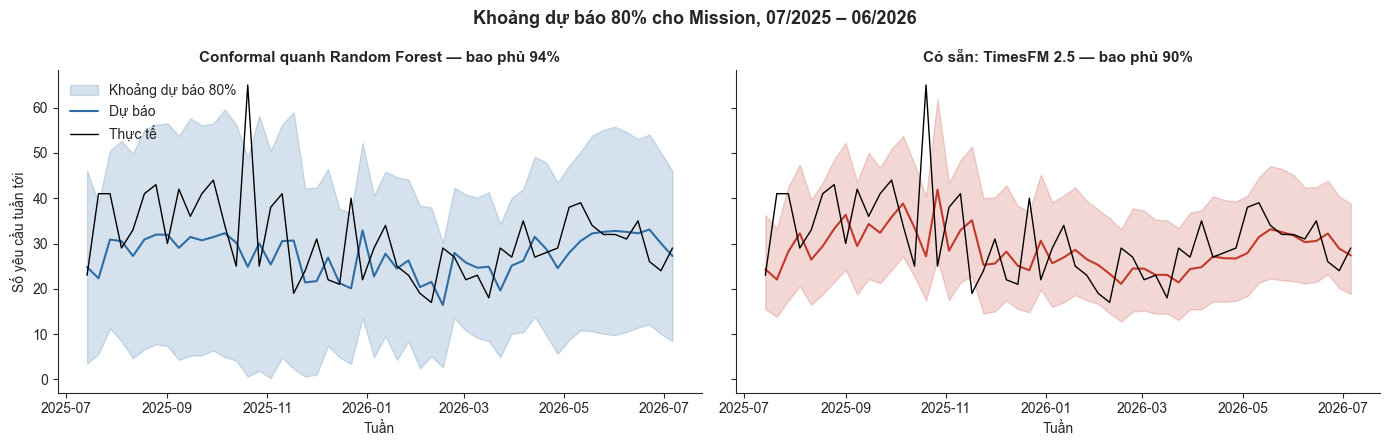

In [7]:
# Biểu đồ 2: minh hoạ khoảng 80% cho Mission (khu phố nhiều yêu cầu nhất), hai mốc cuối (07/2025 – 06/2026)
ve = [f"Conformal quanh {TOT_HUAN_LUYEN}", f"Có sẵn: {TOT_NEN_TANG}"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, pp, mau in zip(axes, ve, ["#2E6DA4", "#C0392B"]):
    m = khoang[(khoang["muc"] == 0.8) & (khoang["phuong_phap"] == pp) & (khoang["nbhd"] == "Mission")
               & (khoang["moc"] >= MOC[-2])].sort_values("week_start")
    tuan_toi = m["week_start"] + pd.Timedelta(days=7)
    ax.fill_between(tuan_toi, m["duoi"], m["tren"], color=mau, alpha=0.2, label="Khoảng dự báo 80%")
    ax.plot(tuan_toi, m["du_bao"], color=mau, linewidth=1.5, label="Dự báo")
    ax.plot(tuan_toi, m["y"], color="black", linewidth=1, label="Thực tế")
    ax.set_title(f"{pp} — bao phủ {m['trong_khoang'].mean() * 100:.0f}%", fontsize=11, fontweight="bold")
    ax.set_xlabel("Tuần")
    sns.despine(ax=ax)
axes[0].set_ylabel("Số yêu cầu tuần tới")
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Khoảng dự báo 80% cho Mission, 07/2025 – 06/2026", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_u02_interval_mission.png", dpi=300)
plt.show()

**Nhận xét:** Độ bao phủ theo giai đoạn

**Vì sao làm bước này?** Một khoảng dự báo có độ bao phủ trung bình đạt mục tiêu vẫn có thể hụt nặng đúng vào lúc dữ liệu đổi hướng — lúc đội bảo trì cần nó nhất. Tách theo giai đoạn cho biết phương pháp nào giữ được độ tin cậy sau điểm gãy.

**Kết quả cần đọc:**
- **Khoảng conformal hụt ở mốc chứa điểm gãy rồi hồi phục ngay**: độ bao phủ (mục tiêu 80%) giảm còn **73.9–76.6%** ở mốc 01/2024, rồi trở lại **81.6–82.8%** ở 4 mốc sau điểm gãy. Ngưỡng của mốc 01/2024 được hiệu chuẩn trên đoạn 07/2023 — một giai đoạn ít biến động — trong khi mốc này có hai trận bão lớn (Notebook 4).
- **Khoảng có sẵn của mô hình nền tảng ổn định nhưng luôn thiếu**: khoảng **73–79%** ở cả ba giai đoạn — không phụ thuộc vào việc hiệu chuẩn nên không bị điểm gãy ảnh hưởng, nhưng cũng không đạt mục tiêu ở giai đoạn nào.
- Minh hoạ ở Mission (khu phố nhiều yêu cầu nhất): khoảng conformal quanh Random Forest **rất rộng** (khoảng 5–55 yêu cầu) và bao phủ **94%** — quá thận trọng, vì dùng chung một hệ số cho mọi khu phố; khoảng có sẵn của TimesFM 2.5 **bám sát mức nhu cầu**, hẹp hơn nhiều mà vẫn bao phủ đúng **90%**.
- → Hai cách bổ sung cho nhau: khoảng có sẵn cho hình dạng khoảng hợp lý ở từng khu phố nhưng thiếu độ bao phủ ở một số khu, còn khoảng conformal bảo đảm độ bao phủ chung nhưng phản ứng chậm khi dữ liệu đổi hướng. Hiệu chuẩn lại khoảng có sẵn bằng conformal là hướng cải thiện tự nhiên.

## **4. Cảnh báo tuần cao điểm**

Một tuần của khu phố là **tuần cao điểm** nếu số yêu cầu vượt **phân vị 90% của 52 tuần gần nhất** của chính khu phố đó (giống Notebook 5). So sánh các cách cảnh báo trên cùng 8 mốc:
- **Tuần này đã cao:** cảnh báo nếu tuần hiện tại vượt ngưỡng (cách đơn giản nhất, không cần mô hình).
- **Dự báo điểm vượt ngưỡng** — của mô hình huấn luyện riêng tốt nhất và mô hình nền tảng tốt nhất.
- **Cận trên khoảng 80% vượt ngưỡng** — khoảng conformal quanh mô hình huấn luyện riêng tốt nhất, và khoảng có sẵn của mô hình nền tảng tốt nhất.

Đánh giá bằng **precision** (trong các lần cảnh báo, bao nhiêu phần trăm đúng), **recall** (bắt được bao nhiêu phần trăm tuần cao điểm), **F1** và **tỷ lệ báo động giả**.

In [8]:
def chi_so_canh_bao(ten, canh_bao, thuc_te):
    tp = (canh_bao & thuc_te).sum()
    fp = (canh_bao & ~thuc_te).sum()
    fn = (~canh_bao & thuc_te).sum()
    tn = (~canh_bao & ~thuc_te).sum()
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    return {"cach_canh_bao": ten, "so_lan_canh_bao": int(tp + fp),
            "precision": precision, "recall": recall,
            "F1": 2 * precision * recall / (precision + recall) if precision + recall else 0,
            "ty_le_bao_dong_gia": fp / (fp + tn)}

def lay(pp, muc=0.8):
    d = khoang[(khoang["muc"] == muc) & (khoang["phuong_phap"] == pp)]
    return d.dropna(subset=["nguong_cao"]).set_index(["nbhd", "week_start"]).sort_index()

goc = lay(f"Conformal quanh {TOT_HUAN_LUYEN}")
nen = lay(f"Có sẵn: {TOT_NEN_TANG}").reindex(goc.index)
thuc_te = goc["y"] > goc["nguong_cao"]
nguong = goc["nguong_cao"]

canh_bao = pd.DataFrame([
    chi_so_canh_bao("Tuần này đã cao", goc["n"] > nguong, thuc_te),
    chi_so_canh_bao(f"Dự báo điểm: {TOT_HUAN_LUYEN}", goc["du_bao"] > nguong, thuc_te),
    chi_so_canh_bao(f"Dự báo điểm: {TOT_NEN_TANG}", nen["du_bao"] > nguong, thuc_te),
    chi_so_canh_bao(f"Cận trên 80% (conformal quanh {TOT_HUAN_LUYEN})", goc["tren"] > nguong, thuc_te),
    chi_so_canh_bao(f"Cận trên 80% (có sẵn: {TOT_NEN_TANG})", nen["tren"] > nguong, thuc_te),
]).round(3)
print(f"Tỷ lệ tuần cao điểm thực tế: {thuc_te.mean() * 100:.1f}% ({int(thuc_te.sum()):,}/{len(thuc_te):,} khu phố – tuần)")
canh_bao

Tỷ lệ tuần cao điểm thực tế: 12.3% (1,046/8,528 khu phố – tuần)


,cach_canh_bao,so_lan_canh_bao,precision,recall,F1,ty_le_bao_dong_gia
0,Tuần này đã cao,948,0.252,0.228,0.240,0.095
1,Dự báo điểm: Random Forest,511,0.196,0.096,0.128,0.055
2,Dự báo điểm: TimesFM 2.5,163,0.221,0.034,0.060,0.017
3,Cận trên 80% (conformal quanh Random Forest),4085,0.172,0.672,0.274,0.452
4,Cận trên 80% (có sẵn: TimesFM 2.5),3566,0.179,0.611,0.277,0.391


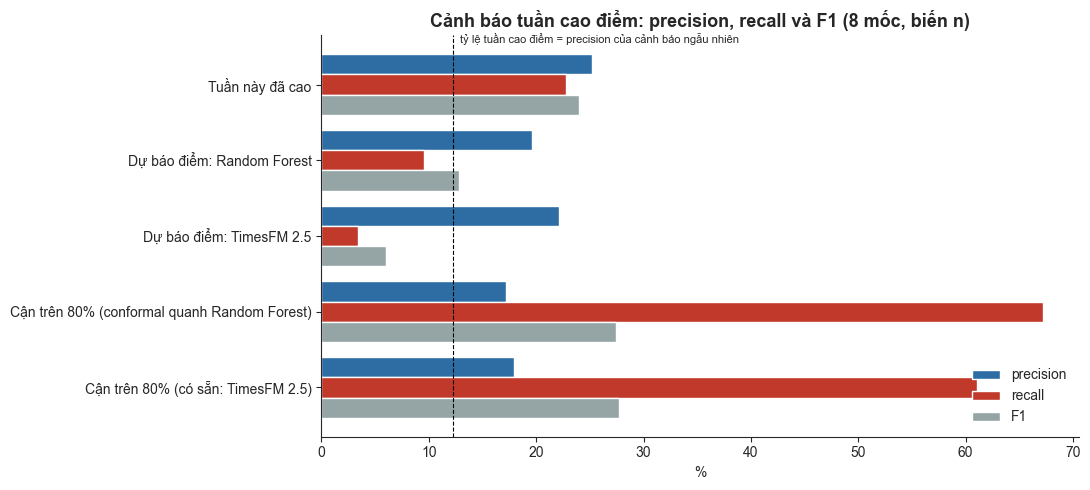

In [9]:
# Biểu đồ 3: precision và recall của các cách cảnh báo
d = canh_bao.set_index("cach_canh_bao")[["precision", "recall", "F1"]] * 100
ax = d.plot(kind="barh", figsize=(11, 5), color=["#2E6DA4", "#C0392B", "#95A5A6"], width=0.8)
ax.axvline(thuc_te.mean() * 100, color="black", linestyle="--", linewidth=0.8)
ax.annotate("tỷ lệ tuần cao điểm = precision của cảnh báo ngẫu nhiên", (thuc_te.mean() * 100, -0.6),
            textcoords="offset points", xytext=(5, 0), fontsize=8, va="center")
ax.invert_yaxis()
sns.despine()
ax.set_xlabel("%")
ax.set_ylabel("")
ax.set_title("Cảnh báo tuần cao điểm: precision, recall và F1 (8 mốc, biến n)", fontsize=13, fontweight="bold")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_u03_alerts.png", dpi=300)
plt.show()

**Nhận xét:** Cảnh báo tuần cao điểm

**Vì sao làm bước này?** Notebook 5 cho thấy cảnh báo dựa trên Ridge hoặc chỉ bắt được rất ít tuần cao điểm, hoặc báo động giả quá nhiều. Ở đây so sánh thêm với phân vị có sẵn của mô hình nền tảng và với cách đơn giản nhất (tuần này đã cao), để biết mô hình có thật sự giúp cảnh báo sớm hay không.

**Kết quả cần đọc:**
- Tuần cao điểm chiếm **12.3%** số khu phố – tuần — đây cũng là precision của một cách cảnh báo ngẫu nhiên.
- **Cách đơn giản nhất ("tuần này đã cao") cạnh tranh tốt nhất**: precision **25.2%**, recall **22.8%**, F1 **0.240**, chỉ **9.5%** báo động giả.
- **Dự báo điểm gần như không bắt được tuần cao điểm**: recall chỉ **9.6%** (Random Forest) và **3.4%** (TimesFM 2.5), vì dự báo điểm trơn và hiếm khi vượt ngưỡng.
- **Cận trên của khoảng 80%** bắt được **61–67%** số tuần cao điểm, nhưng đổi lại **39–45%** báo động giả và precision chỉ **17–18%** — chỉ hơn cảnh báo ngẫu nhiên khoảng 1.4 lần. F1 cao nhất (**0.277**, cận trên có sẵn của TimesFM 2.5) chỉ nhỉnh hơn cách "tuần này đã cao"; cận trên có sẵn báo động ít hơn và ít báo động giả hơn cận trên conformal (39% so với 45%).
- → **Chưa có cách nào cảnh báo sớm tuần quá tải một cách đáng tin cậy**, kể cả với mô hình nền tảng: đột biến chủ yếu do **bão**, mà mọi mô hình chỉ biết dữ liệu đến hết tuần hiện tại. Cảnh báo tốt hơn cần thông tin **nhìn trước** như dự báo thời tiết hoặc cảnh báo bão (hướng phát triển).

## **5. Xuất bảng kết quả**

In [10]:
do_tin_cay.to_csv("../Outputs/tables/unc_01_interval_reliability.csv", index=False)
bp_gd.to_csv("../Outputs/tables/unc_02_coverage_by_regime.csv")
canh_bao.to_csv("../Outputs/tables/unc_03_alerts.csv", index=False)
print("Đã lưu xong 3 biểu đồ và 3 bảng kết quả.")

Đã lưu xong 3 biểu đồ và 3 bảng kết quả.
